<a href="https://colab.research.google.com/github/pachterlab/monod/blob/main/demos/monod_walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *Monod* on Colab

In the current notebook, we apply *Monod* to identify differentially regulated genes between GABAergic and glutamatergic cell types in a single Allen dataset.

# Inference pipeline

## Import Prerequisites

In [ ]:
!pip install -q scanpy

## Install Monod

This installs the pure-Python package. The optional Rust extension (`monod_core`) needs a Rust toolchain and is not built on Colab; everything below runs on the Python code path, just more slowly.

In [ ]:
!git clone -q https://github.com/pachterlab/monod.git
%cd monod
!pip install -q ./
%cd ../

In [3]:
from monod import extract_data, cme_toolbox, inference, analysis, mminference
from monod.inference import search_result_from_uns, search_result_list_from_uns, searchdata_from_adata
print('monod', __import__('monod').__version__)

monod 0.4.0


## Import data

In [4]:
! git clone https://github.com/pachterlab/monod_examples.git
%cd monod_examples
!git checkout anndata
%cd ../

Cloning into 'monod_examples'...


remote: Enumerating objects: 1983, done.


remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (97/97), done.


remote: Total 1983 (delta 72), reused 46 (delta 46), pack-reused 1839 (from 1)
Receiving objects: 100% (1983/1983), 1.31 GiB | 7.40 MiB/s, done.


Resolving deltas: 100% (865/865), done.


Updating files: 100% (120/120), done.


/Users/ConradOakes/monod/monod_examples


branch 'anndata' set up to track 'origin/anndata'.
Switched to a new branch 'anndata'


/Users/ConradOakes/monod


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import anndata
from IPython.display import display, Markdown
import scanpy as sc
import anndata as ad
import numpy as np
import os
import zlib
import math
import argparse
from pathlib import Path

In [6]:
import logging, sys
logging.basicConfig(stream=sys.stdout)
logging.getLogger('monod').setLevel(logging.INFO)   # progress messages from monod only

import warnings
warnings.filterwarnings('ignore')

The printed version above should be 0.3.0 or later; the cells below use that API.

## Import data

In [7]:
def decompress_chunk(compressed_data):
    """Decompress a zlib-compressed bytes object"""
    return zlib.decompress(compressed_data)

def combine_chunks(input_dir, output_file):
    """Combine compressed chunks back into a single h5ad file"""
    # Get all chunk files sorted by name
    chunk_files = sorted(Path(input_dir).glob('chunk_*.gz'))

    # Combine chunks
    combined_data = bytes()
    for chunk_file in chunk_files:
        with open(chunk_file, 'rb') as f:
            compressed_chunk = f.read()
        chunk = decompress_chunk(compressed_chunk)
        combined_data += chunk
        print(f'Processed chunk: {chunk_file}')

    # Write combined data to temporary file
    with open('temp_combined.h5ad', 'wb') as f:
        f.write(combined_data)

    # Load and save as AnnData to ensure proper format
    adata = ad.read_h5ad('temp_combined.h5ad')
    adata.write(output_file)#, compression='gzip')

    # Clean up temporary file
    os.remove('temp_combined.h5ad')
    print(f'Successfully created combined file: {output_file}')

In [8]:
combine_chunks('monod_examples/sample_data/gaba_anndata', 'gaba_example.h5ad')
combine_chunks('monod_examples/sample_data/glu_anndata', 'glu_example.h5ad')

Processed chunk: monod_examples/sample_data/gaba_anndata/chunk_0000.gz


Processed chunk: monod_examples/sample_data/gaba_anndata/chunk_0001.gz


Successfully created combined file: gaba_example.h5ad
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0000.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0001.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0002.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0003.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0004.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0005.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0006.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0007.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0008.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0009.gz


Successfully created combined file: glu_example.h5ad


### Load data and filter if desired

In [9]:
glu_adata = anndata.read_h5ad('./glu_example.h5ad')

In [10]:
gaba_adata = anndata.read_h5ad('./gaba_example.h5ad')

Create knee plot.

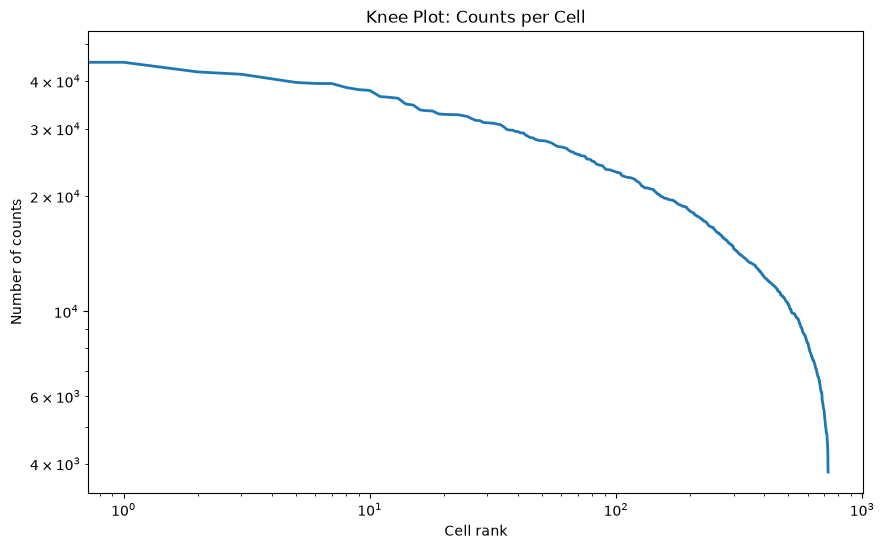

In [11]:
# Calculate number of genes per cell
sc.pp.calculate_qc_metrics(gaba_adata, inplace=True)

# Sort cells by number of genes
total_counts = np.sort(gaba_adata.obs.total_counts)[::-1]

# Create range for x-axis
cell_range = range(len(total_counts))

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(cell_range, total_counts, linewidth=2)

plt.xlabel('Cell rank')
plt.ylabel('Number of counts')
plt.title('Knee Plot: Counts per Cell')

# Add log scales
plt.xscale('log')
plt.yscale('log')

plt.show()

Filter by number of counts if desired.

In [12]:
threshold = 10
sc.pp.filter_cells(gaba_adata, min_counts=threshold)
sc.pp.filter_cells(glu_adata, min_counts=threshold)

## Set up model and perform inference.

Optional Fit Parameters

In [13]:
transcriptome_filepath =  './monod_examples/polyA_ref/gg_200524_mouse_genome_polyA_cum_1'
demo_genes = ['Eif5b','Xrcc5','Klhl12','Rgs7','Thsd7b']
lb, ub, samp_lb, samp_ub, gridsize = None, None, None, None, None # Can add as keywords if desired.

INFO:monod:No dataset name given (dataset_string=None). Saving as Bursty_Poisson


INFO:monod:Beginning data extraction.


INFO:monod:Dataset: Bursty_Poisson


INFO:monod:Reading layers ['unspliced', 'spliced']. If your AnnData layers use other names, pass modality_name_dict={<modality>: <layer>, ...}.


INFO:monod:Added lengths


...

INFO:monod:Starting non-parallelized Hessian computation.


INFO:monod:Non-parallelized Hessian computation complete.


INFO:monod:Standard error of the MLE computation complete. Runtime: 0.3 seconds.


INFO:monod:Uncertainties per gene calculated, saved to anndata in .var attribute of the form: "error_$\gamma$". Note that the errors are given for log-base 10 parameters.


INFO:monod:Search data is not stored; rebuild it with searchdata_from_adata(monod_adata).


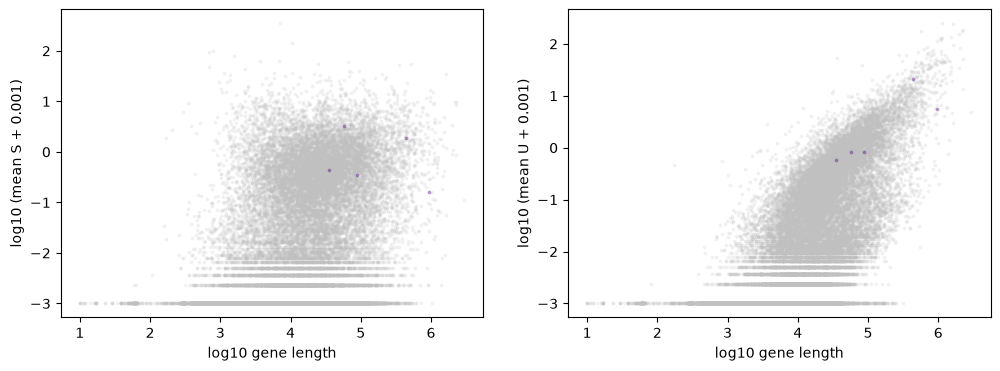

In [14]:
# Define model.
fitmodel = cme_toolbox.CMEModel('Bursty','Poisson')

# Define number of clusters and epochs if using meK-Means, otherwise set to None.
mek_means_params = None # (4,2)

gaba_adata = inference.perform_inference(gaba_adata, fitmodel, genes_to_fit=demo_genes,
                                         transcriptome_filepath=transcriptome_filepath,
                                         num_cores=16, mek_means_params=mek_means_params, n_genes=2,
                                         exclude_sigma = False)

INFO:monod:Beginning data extraction.


INFO:monod:Dataset: glu_example


INFO:monod:Reading layers ['unspliced', 'spliced']. If your AnnData layers use other names, pass modality_name_dict={<modality>: <layer>, ...}.


INFO:monod:Duplicate variable names found. Making them unique...


INFO:monod:Added lengths


...

INFO:monod:Starting non-parallelized Hessian computation.


INFO:monod:Non-parallelized Hessian computation complete.


INFO:monod:Standard error of the MLE computation complete. Runtime: 0.2 seconds.


INFO:monod:Uncertainties per gene calculated, saved to anndata in .var attribute of the form: "error_$\gamma$". Note that the errors are given for log-base 10 parameters.


INFO:monod:Search data is not stored; rebuild it with searchdata_from_adata(monod_adata).


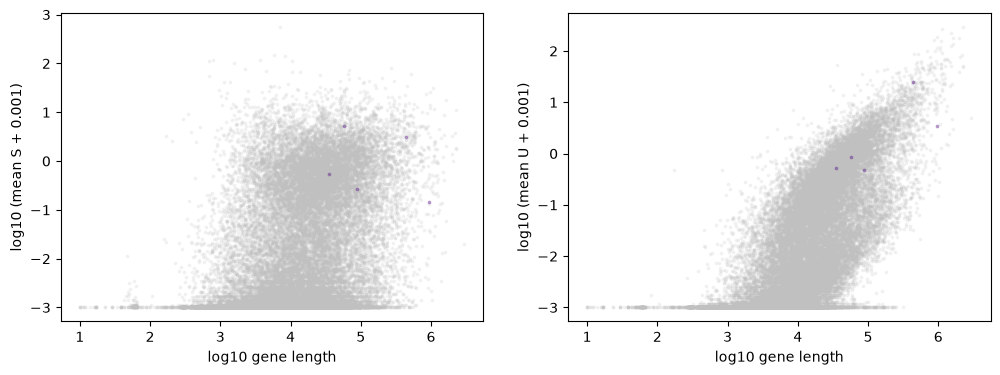

In [15]:
# Fix the genes to be the same as for the gaba data.
genes_to_fit = [i for i in gaba_adata.var_names]
n_genes = len(genes_to_fit)

glu_adata = inference.perform_inference('./glu_example.h5ad', fitmodel, n_genes=n_genes, genes_to_fit=genes_to_fit,
                transcriptome_filepath=transcriptome_filepath, mek_means_params=mek_means_params, num_cores=16,
                                         exclude_sigma = False)

## Access gene info.

In [16]:
# AIC.
display(gaba_adata.var[['AIC']])

# Optimum biological parameters and associated errors.
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if '$' in i]])

,AIC
Eif5b,5073.598870
Xrcc5,2900.436196
Klhl12,2826.160827
Rgs7,8317.433133
Thsd7b,4417.919920


,$b$,$\beta$,$\gamma$,error_$b$,error_$\beta$,error_$\gamma$
Eif5b,1.172837,-0.175999,-0.341383,0.045045,0.044166,0.044646
Xrcc5,1.374601,0.205610,0.819412,0.050675,0.043932,0.054704
Klhl12,1.165873,-0.251265,0.527014,0.080235,0.077213,0.082205
Rgs7,1.709502,-0.167372,0.426097,0.026477,0.022899,0.027416
Thsd7b,1.278201,0.309663,1.070016,0.036484,0.026823,0.052046


In [17]:
# AIC.
display(glu_adata.var[['AIC']])

# Optimum biological parameters and associated errors.
display(glu_adata.var[[i for i in glu_adata.var.keys() if '$' in i]])

,AIC
Eif5b,50406.627448
Xrcc5,21098.899156
Klhl12,26314.937293
Rgs7,81175.388155
Thsd7b,33819.385672


,$b$,$\beta$,$\gamma$,error_$b$,error_$\beta$,error_$\gamma$
Eif5b,3.104041,-0.081362,-0.602128,0.013306,0.013094,0.013258
Xrcc5,2.740959,0.006486,0.303527,0.024510,0.023428,0.025630
Klhl12,2.844693,-0.323647,0.106714,0.029461,0.028870,0.029812
Rgs7,3.396680,-0.352550,-0.094606,0.008524,0.007762,0.008850
Thsd7b,3.005550,0.432837,0.862566,0.013166,0.009411,0.017552


## Plot parameter distributions.

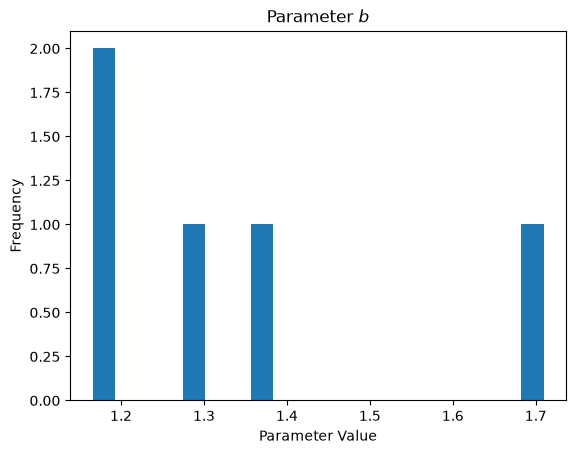

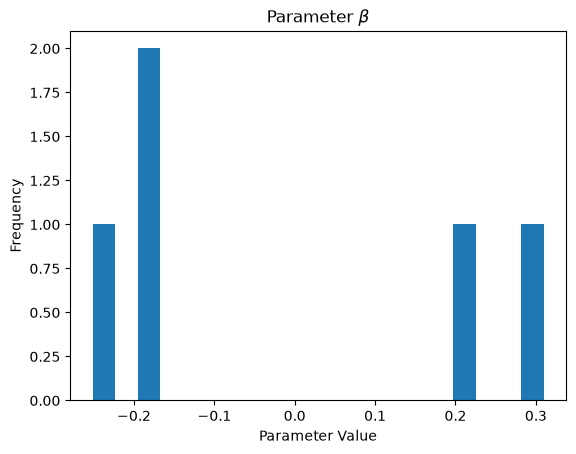

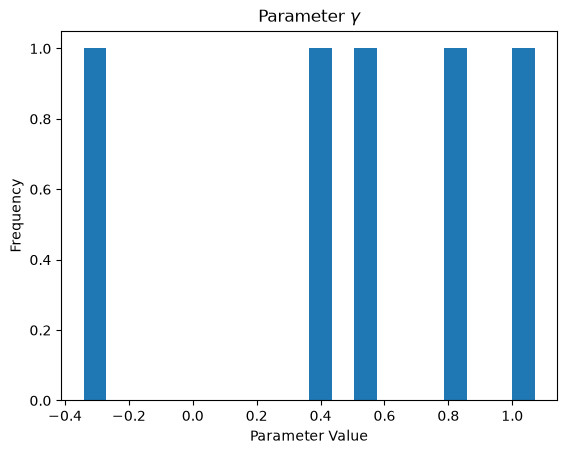

In [18]:
param_names = [i for i in gaba_adata.var.keys() if '$' in i and 'error' not in i]
for name in param_names:
    plt.hist(gaba_adata.var[name], bins=20)
    plt.title('Parameter ' + name)
    plt.xlabel('Parameter Value')
    plt.ylabel('Frequency')
    # plt.savefig(search_result.inference_string + '/parameter_dist_'+ str(i))#'/parameter_dist_{}'.format(
    plt.show()

# Analysis

## Reject genes.

In [19]:
# Chi-square goodness-of-fit testing; flags poorly fit genes in .var and in the stored results.
gaba_adata = inference.reject_genes(gaba_adata, reject_at_bounds=False, mek_means=mek_means_params)
glu_adata = inference.reject_genes(glu_adata, reject_at_bounds=False, mek_means=mek_means_params)

# Show rejected genes.
display(glu_adata.var[[i for i in glu_adata.var.keys() if 'rejected' in i]])
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if 'rejected' in i]])

# Show chi-squared values and the other rejection statistics.
display(glu_adata.var[[i for i in glu_adata.var.keys() if 'csq' in i or 'pval' in i or 'hellinger' in i]])
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if 'csq' in i or 'pval' in i or 'hellinger' in i]])

INFO:monod:Chi-square computation complete (Rust). Rejected 2 genes out of 5. Runtime: 0.0 seconds.


INFO:monod:Rejected 2/5 genes; flags stored in adata.var['rejected_genes'].


INFO:monod:Chi-square computation complete (Rust). Rejected 1 genes out of 5. Runtime: 0.0 seconds.


INFO:monod:Rejected 1/5 genes; flags stored in adata.var['rejected_genes'].


,rejected_genes
Eif5b,False
Xrcc5,False
Klhl12,False
Rgs7,True
Thsd7b,False


,rejected_genes
Eif5b,False
Xrcc5,False
Klhl12,False
Rgs7,True
Thsd7b,True


,csq,pval,hellinger
Eif5b,231.436486,1.014311e-15,0.011614
Xrcc5,131.019130,4.068952e-20,0.004970
Klhl12,164.884980,2.837623e-25,0.006302
Rgs7,1092.416828,3.719834e-67,0.055712
Thsd7b,469.458189,6.856998e-61,0.018261


,csq,pval,hellinger
Eif5b,57.211713,4.003820e-03,0.034285
Xrcc5,21.348415,4.550541e-02,0.023882
Klhl12,25.756594,4.081719e-03,0.018318
Rgs7,250.500656,7.505242e-22,0.225944
Thsd7b,82.314177,3.362553e-10,0.082910


In [20]:
#dir(glu_adata.uns['search_result'])

## Execute differential expression analysis.

Fold changes saved to each dataframe under .var, e.g. FC_$\gamma$
Adjusted parameter values (subtracting the average fold change) saved to the second dataframe under .var, e.g. adj_$\gamma$
Adjusted fold changes (subtracting the average fold change) saved to each dataframe under .var, e.g. adj_FC_$\gamma$


,FC_$b$,adj_FC_$b$,FC_$\beta$,adj_FC_$\beta$,FC_$\gamma$,adj_FC_$\gamma$
Eif5b,-1.931204,-0.234945,-0.094636,-0.140031,0.260745,-0.104847
Xrcc5,-1.366359,0.329900,0.199124,0.153729,0.515885,0.150293
Klhl12,-1.678820,0.017439,0.072382,0.026986,0.420300,0.054708
Rgs7,NaN,NaN,NaN,NaN,NaN,NaN
Thsd7b,NaN,NaN,NaN,NaN,NaN,NaN


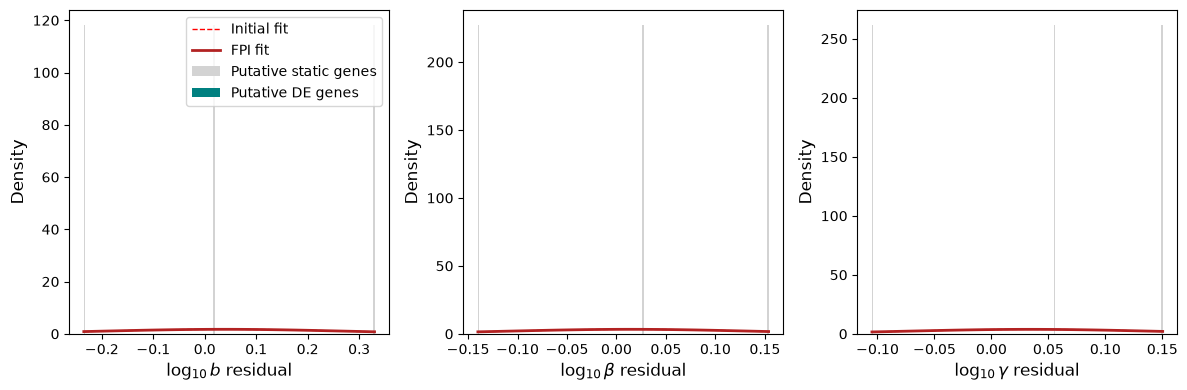

In [21]:
# If 2 anndata objects are given, parameters are compared across datasets.
if not mek_means_params:
    DE_genes, DE_filter, offs, residuals = analysis.DE_parameters(glu_adata, gaba_adata,
                                                                  viz=True, use_sigma=True)

# If using meK-Means, compare clusters within one dataset.
else:
    DE_genes_gaba, DE_filter_gaba, offs_gaba, residuals_gaba = analysis.DE_parameters(gaba_adata,
                                                                  viz=True, use_sigma=True, discard_rejected=True,
                                                                  save_cluster_FCs=False)
    clusters = [i for i in DE_genes_gaba.keys()]
    DE_genes = [DE_genes_gaba[i] for i in clusters]
    sr_list = search_result_list_from_uns(gaba_adata.uns['search_result_list'])
    param_names = sr_list[0].model.get_log_name_str()
    param_num, cluster_num = 0, 0
    display(Markdown('E.g. ' + param_names[param_num]))
    print(clusters[cluster_num], DE_genes[cluster_num][param_num])

# Fold-change columns follow the parameter naming ($b$, $\\beta$, $\\gamma$).
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if 'FC' in i]])

### Show some gene distributions.

Results are stored in `adata.uns` as plain dictionaries (no pickling). `search_result_from_uns` rebuilds the `SearchResults` object and `searchdata_from_adata` rebuilds the per-gene histograms from the layers; the plotting methods then take both.

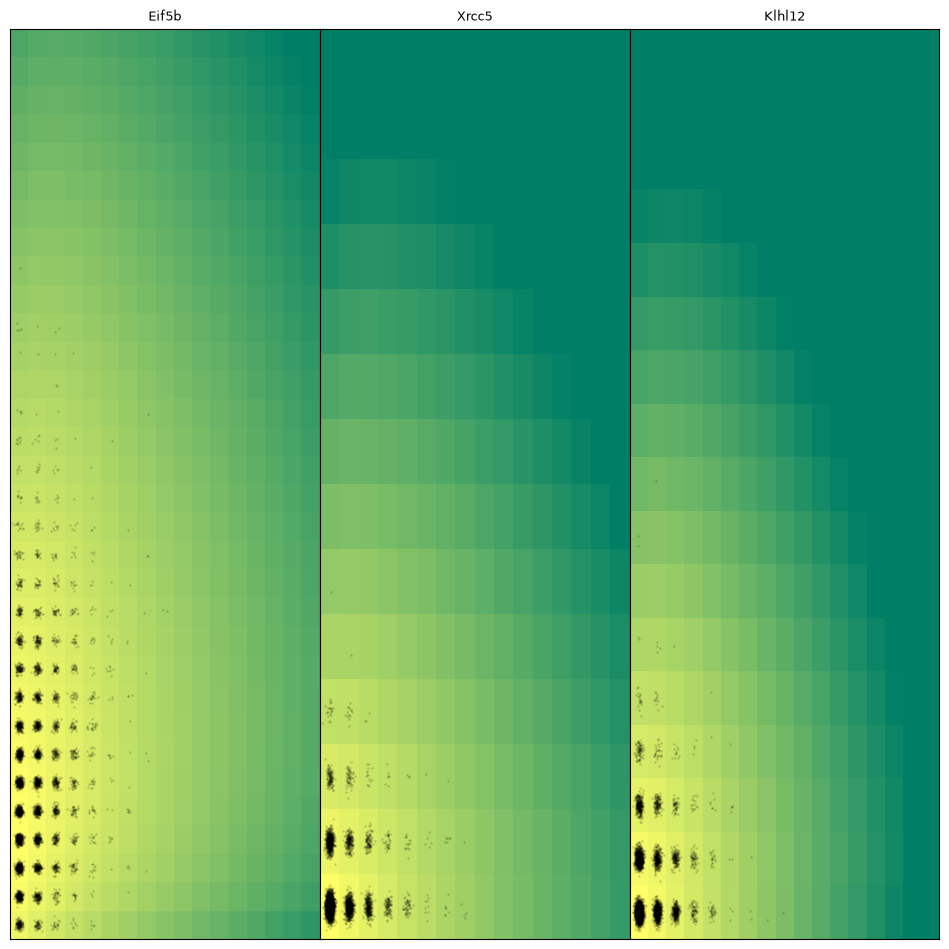

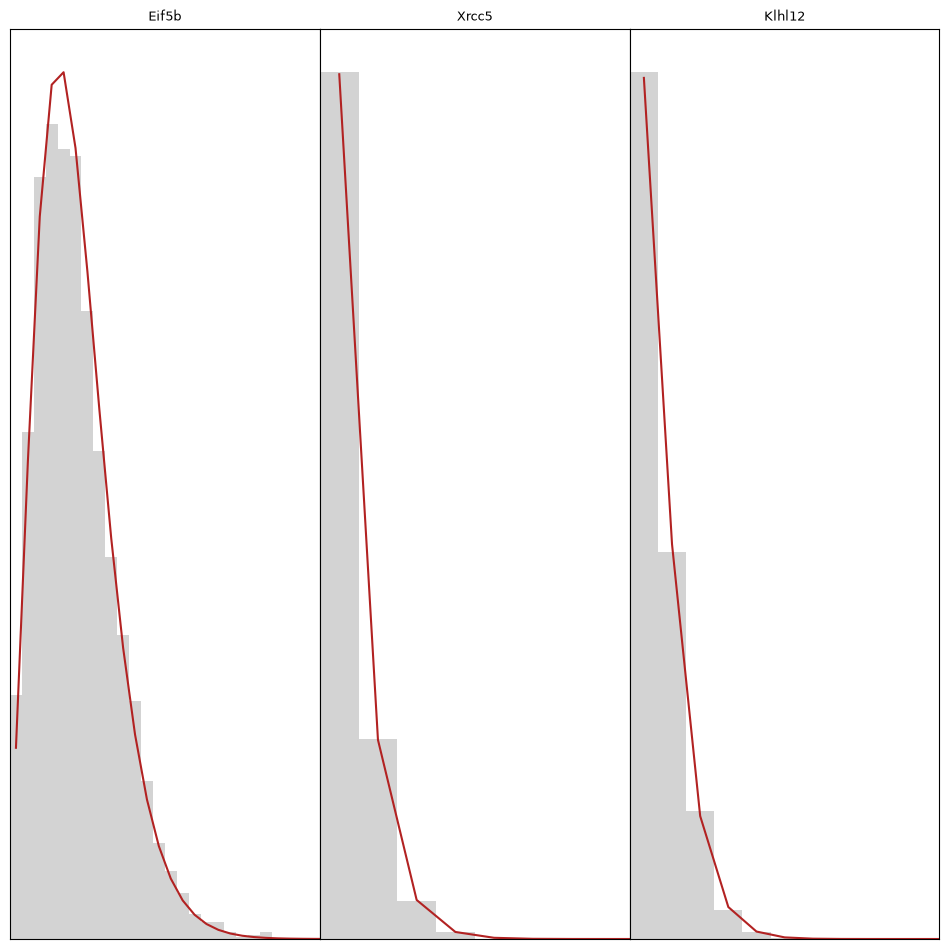

In [22]:
fitted_adata = glu_adata
search_result = search_result_from_uns(fitted_adata.uns['search_result'])
search_data = searchdata_from_adata(fitted_adata)

# Joint (unspliced x spliced) distributions with the fitted model, then the spliced marginals.
search_result.plot_gene_distributions(search_data, sz=(1, 3), marg='joint', savefig=False)
search_result.plot_gene_distributions(search_data, sz=(1, 3), marg='spliced', savefig=False)
plt.show()

INFO:monod:Run directory /home/coakes/monod/demos/Bursty_Poisson/Bursty_Poisson_6x7 does not exist (run with save=True to create it); kldiv.png not saved.


INFO:monod:Run directory /home/coakes/monod/demos/Bursty_Poisson/Bursty_Poisson_6x7 does not exist (run with save=True to create it); gene_distributions_joint.png not saved.


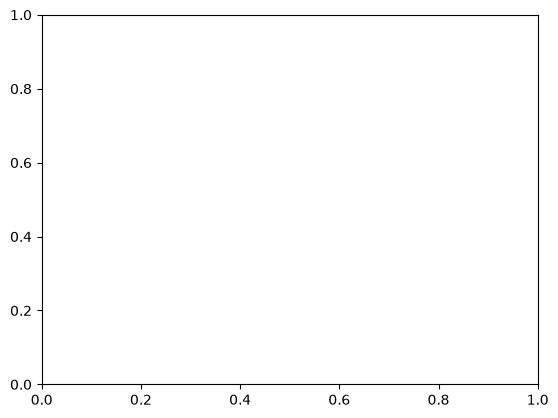

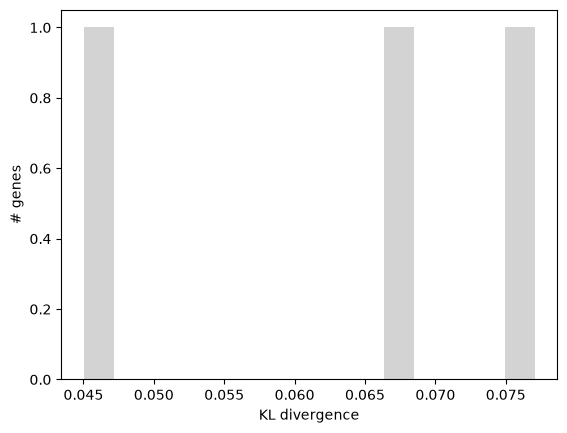

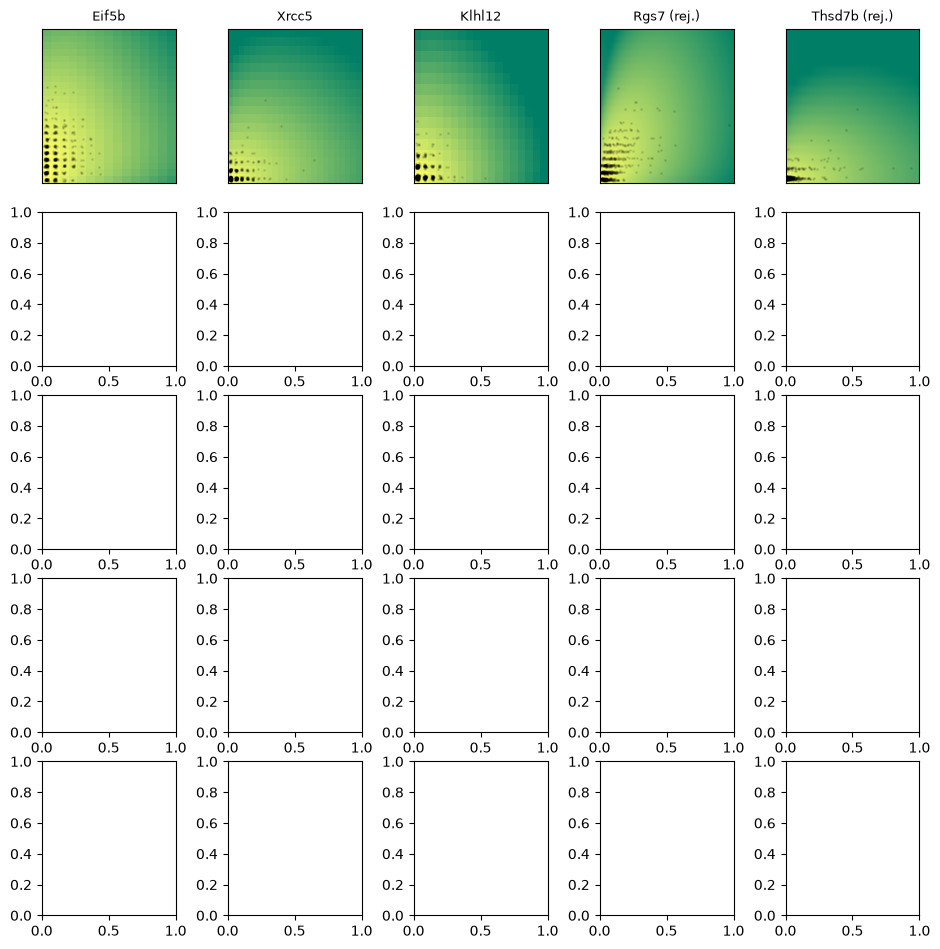

In [23]:
# Quick QC summary for a fitted AnnData: KL-divergence histogram and joint gene distributions.
analysis.run_qc(gaba_adata, mek_means_params=mek_means_params)